# W&B charts of the embedding experiment (KAN-99)
Gözde Nur Özdemir · ELIZA · Sprint 2

This notebook reads the tables that `src/embedding.ipynb` logged in its W&B run and adds the charts to the same run: the LLM jury, word removal for BM25 (stopwords, jury, frequent words), the embedding models and weights, removal before embedding, top-k and every val question. It also saves all charts in one PDF, `embedding-results.pdf`.

**How to run:** in Colab, *Runtime → Run all* (a CPU is enough, about 1 minute). It asks for your W&B key.

In [1]:
%pip -q install wandb pandas matplotlib

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: gozdenur104 (gozdenur104-metu-middle-east-technical-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  


Saved embedding-results.pdf


Charts added to: https://wandb.ai/gozdenur104-metu-middle-east-technical-university/eliza-rag/runs/oyrsrqwf


final/Capped recall@5,0.51
final/Capped recall@8,0.58
final/MRR,0.69
final/Precision@5,0.24
final/Precision@8,0.19
final/Recall@5,0.48
final/Recall@8,0.56


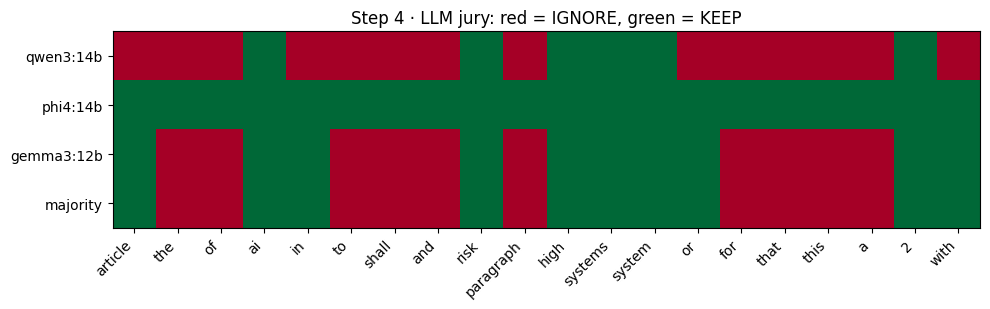

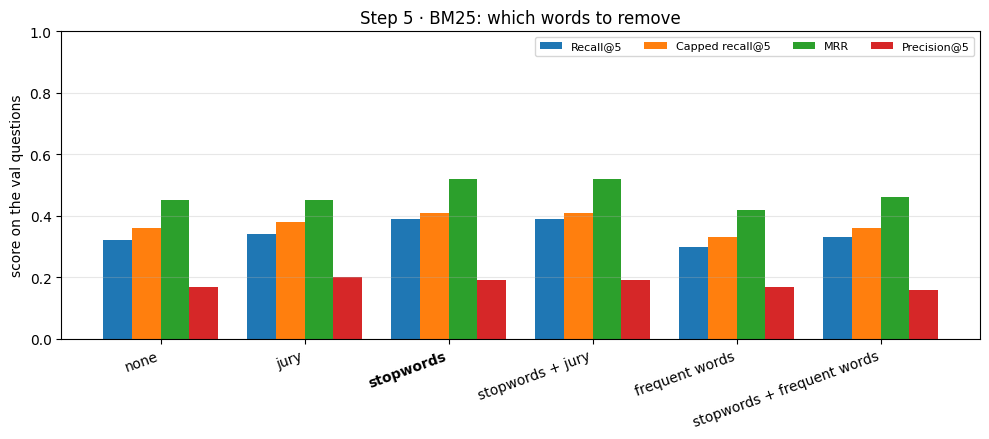

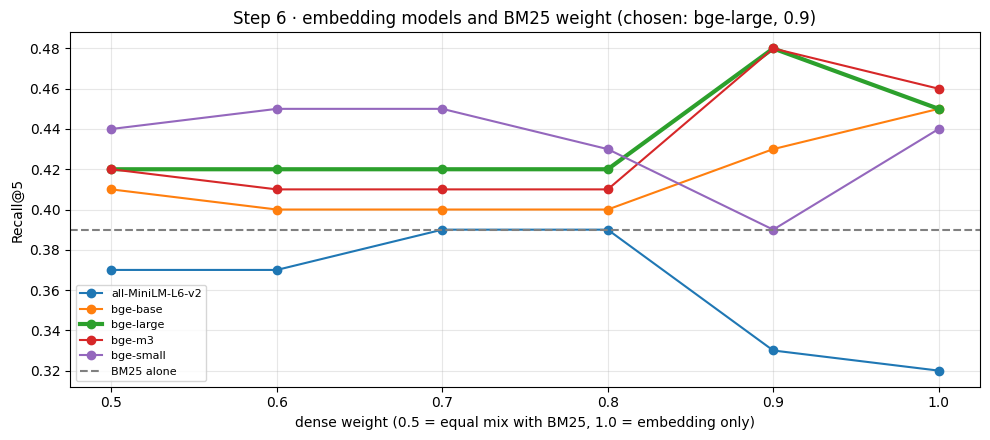

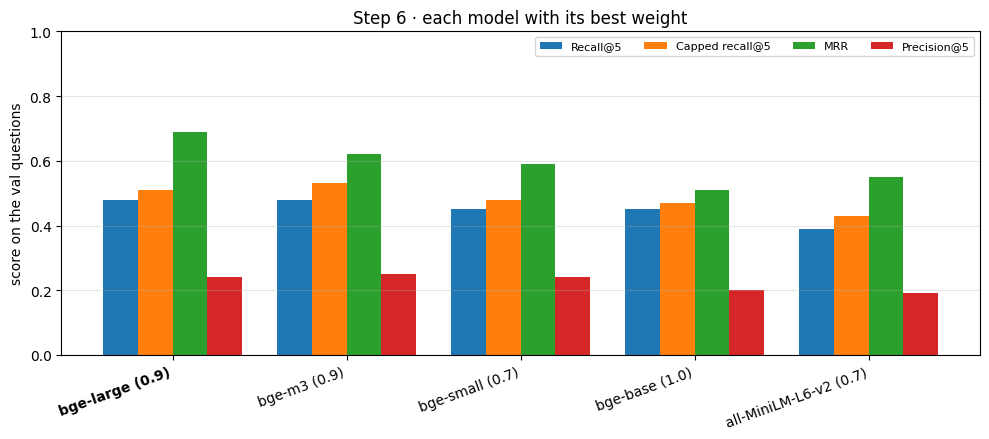

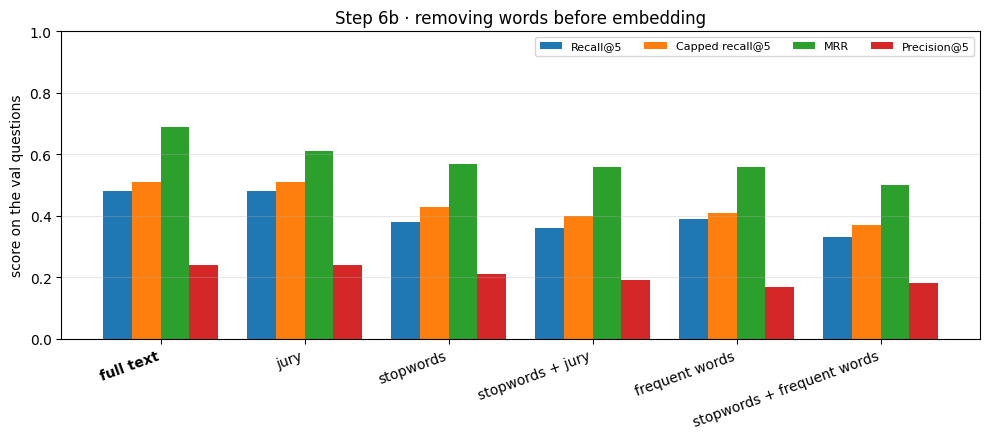

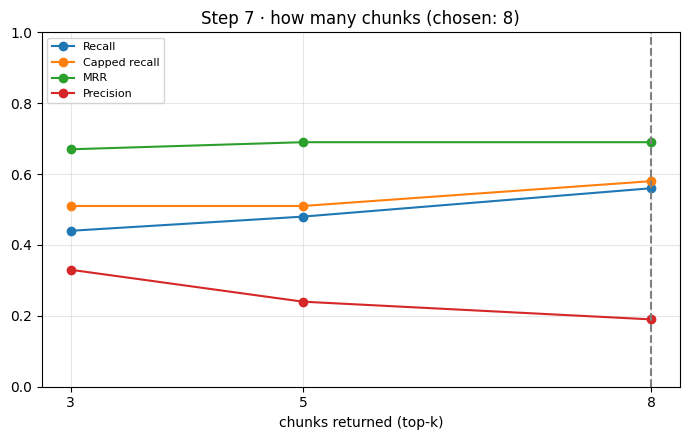

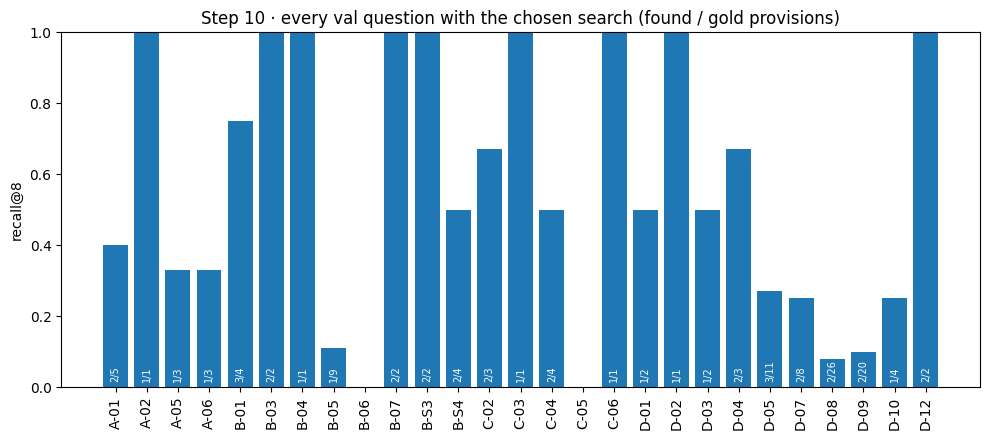

In [2]:
# Adds the charts of the embedding experiment to the W&B run that is already there (no need to run the notebook again).
# Colab (CPU is enough) or your computer:  pip install wandb pandas matplotlib   then run this cell.
import numpy as np, pandas as pd, wandb
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

ENTITY, PROJECT, RUN_ID = "gozdenur104-metu-middle-east-technical-university", "eliza-rag", "oyrsrqwf"
PDF_FILE = "embedding-results.pdf"
METRICS = ["Recall@5", "Capped recall@5", "MRR", "Precision@5"]
JURY = ["qwen3:14b", "phi4:14b", "gemma3:12b"]

wandb.login()
api = wandb.Api()

def table(key):
    """Reads a table that the notebook logged in the run, as a pandas DataFrame."""
    t = api.artifact(f"{ENTITY}/{PROJECT}/run-{RUN_ID}-{key}:latest").get(key)
    return pd.DataFrame(t.data, columns=t.columns)

jury, bm25, models = table("step4_jury"), table("step5_bm25_word_removal"), table("step6_models_and_weights")
before, topk, per_q = table("step6b_removal_before_embedding"), table("step7_top_k"), table("val_questions")
config = api.run(f"{ENTITY}/{PROJECT}/{RUN_ID}").config
chosen = config["chosen"]
best_model = chosen["embedding_model"].split("/")[1].replace("-en-v1.5", "")
k_col = [c for c in per_q.columns if c.startswith("recall@")][0]

def bars(df, label_col, title, highlight):
    """Grouped bars: one group per row, one bar per metric; the chosen row's label is bold."""
    fig, ax = plt.subplots(figsize=(10, 4.5))
    x = np.arange(len(df)); w = 0.2
    for n, m in enumerate(METRICS):
        ax.bar(x + (n - 1.5) * w, df[m].astype(float), w, label=m)
    ax.set_xticks(x); ax.set_xticklabels(df[label_col], rotation=20, ha="right")
    for lab in ax.get_xticklabels():
        if lab.get_text() == highlight: lab.set_fontweight("bold")
    ax.set_ylim(0, 1); ax.set_ylabel("score on the val questions"); ax.set_title(title)
    ax.legend(ncol=4, fontsize=8); ax.grid(axis="y", alpha=0.3); fig.tight_layout()
    return fig

figures = {}

# step 4: the jury's votes (red = IGNORE, green = KEEP)
votes = jury.set_index("word")[JURY + ["majority"]]
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.imshow((votes == "IGNORE").T.astype(int), cmap="RdYlGn_r", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(votes))); ax.set_xticklabels(votes.index, rotation=45, ha="right")
ax.set_yticks(range(len(votes.columns))); ax.set_yticklabels(votes.columns)
ax.set_title("Step 4 · LLM jury: red = IGNORE, green = KEEP"); fig.tight_layout()
figures["step4_jury_votes"] = fig

# step 5: word removal for BM25 (stopwords, jury, frequent words ...)
figures["step5_bm25_word_removal"] = bars(bm25, "version", "Step 5 · BM25: which words to remove", chosen["bm25_remove"])

# step 6: Recall@5 of every model and dense weight
fig, ax = plt.subplots(figsize=(10, 4.5))
emb = models[models["model"] != "BM25 only"]
for name, part in emb.groupby("model"):
    ax.plot(part["dense weight"].astype(float), part["Recall@5"].astype(float), marker="o", label=name,
            linewidth=3 if name == best_model else 1.5)
ax.axhline(float(models.loc[models["model"] == "BM25 only", "Recall@5"].iloc[0]), color="grey", linestyle="--", label="BM25 alone")
ax.set_xlabel("dense weight (0.5 = equal mix with BM25, 1.0 = embedding only)"); ax.set_ylabel("Recall@5")
ax.set_title(f"Step 6 · embedding models and BM25 weight (chosen: {best_model}, {chosen['dense_weight']})")
ax.grid(alpha=0.3); ax.legend(fontsize=8); fig.tight_layout()
figures["step6_models_and_weights"] = fig

# step 6: each model with its best weight
best = emb.sort_values(["Recall@5", "MRR"], ascending=False).groupby("model").head(1)
best = best.assign(label=best["model"] + " (" + best["dense weight"].astype(str) + ")")
figures["step6_best_of_each_model"] = bars(best, "label", "Step 6 · each model with its best weight",
                                           f"{best_model} ({chosen['dense_weight']})")

# step 6b: word removal before embedding
figures["step6b_removal_before_embedding"] = bars(before, "before embedding", "Step 6b · removing words before embedding", "full text")

# step 7: top-k
fig, ax = plt.subplots(figsize=(7, 4.5))
for m in ["Recall", "Capped recall", "MRR", "Precision"]:
    ax.plot(topk["top-k"].astype(int), topk[m].astype(float), marker="o", label=m)
ax.axvline(chosen["top_k"], color="grey", linestyle="--")
ax.set_xticks(topk["top-k"].astype(int)); ax.set_xlabel("chunks returned (top-k)"); ax.set_ylim(0, 1)
ax.set_title(f"Step 7 · how many chunks (chosen: {chosen['top_k']})"); ax.grid(alpha=0.3); ax.legend(fontsize=8); fig.tight_layout()
figures["step7_top_k"] = fig

# step 10: every val question
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(per_q["id"], per_q[k_col].astype(float))
for x, (h, g) in enumerate(zip(per_q["hits"], per_q["gold count"])):
    ax.text(x, 0.02, f"{h}/{g}", ha="center", fontsize=7, color="white", rotation=90)
ax.set_ylim(0, 1); ax.set_ylabel(k_col); ax.tick_params(axis="x", rotation=90)
ax.set_title("Step 10 · every val question with the chosen search (found / gold provisions)"); fig.tight_layout()
figures["step10_val_questions"] = fig

# one PDF: a first page with the chosen settings and the final scores, then every chart
final = {k: v for k, v in api.run(f"{ENTITY}/{PROJECT}/{RUN_ID}").summary.items() if k.startswith("final/")}
with PdfPages(PDF_FILE) as pdf:
    fig = plt.figure(figsize=(10, 4.5))
    fig.text(0.05, 0.9, "ELIZA · embedding experiment on the val split (KAN-97, KAN-221, KAN-99)", fontsize=14, weight="bold")
    lines = [f"Val questions scored: {config.get('val_questions_scored')}",
             f"Embedding model: {chosen['embedding_model']}   dense weight: {chosen['dense_weight']}   BM25 words removed: {chosen['bm25_remove']}",
             f"Words removed before embedding: {chosen['remove_before_embedding']}   top-k: {chosen['top_k']}",
             "Final search: " + ", ".join(f"{k[6:]} {round(v, 2)}" for k, v in sorted(final.items())),
             f"W&B run: https://wandb.ai/{ENTITY}/{PROJECT}/runs/{RUN_ID}"]
    for n, line in enumerate(lines):
        fig.text(0.05, 0.75 - n * 0.12, line, fontsize=9)
    pdf.savefig(fig); plt.close(fig)
    for f in figures.values():
        pdf.savefig(f)
print("Saved", PDF_FILE)

# add the charts to the same run: pictures, plus interactive W&B charts for the main comparisons
run = wandb.init(entity=ENTITY, project=PROJECT, id=RUN_ID, resume="must")
logs = {"charts/" + name: wandb.Image(f) for name, f in figures.items()}
for m in ["Recall@5", "MRR"]:
    t = wandb.Table(dataframe=bm25[["version", m]].astype({m: float}))
    logs[f"interactive/step5_bm25_{m}"] = wandb.plot.bar(t, "version", m, title=f"Step 5 · BM25 word removal: {m}")
    t = wandb.Table(dataframe=before[["before embedding", m]].astype({m: float}))
    logs[f"interactive/step6b_{m}"] = wandb.plot.bar(t, "before embedding", m, title=f"Step 6b · removal before embedding: {m}")
weights = sorted(emb["dense weight"].astype(float).unique())
names = sorted(emb["model"].unique())
logs["interactive/step6_recall_by_weight"] = wandb.plot.line_series(
    xs=weights, ys=[[float(emb[(emb["model"] == n) & (emb["dense weight"].astype(float) == w)]["Recall@5"].iloc[0]) for w in weights] for n in names],
    keys=names, title="Step 6 · Recall@5 by dense weight", xname="dense weight")
logs["interactive/step7_top_k"] = wandb.plot.line_series(
    xs=topk["top-k"].astype(int).tolist(), ys=[topk[m].astype(float).tolist() for m in ["Recall", "Capped recall", "MRR", "Precision"]],
    keys=["Recall", "Capped recall", "MRR", "Precision"], title="Step 7 · top-k", xname="top-k")
wandb.log(logs)
artifact = wandb.Artifact("embedding-results", type="report"); artifact.add_file(PDF_FILE); run.log_artifact(artifact)
print("Charts added to:", run.url)
wandb.finish()


In [3]:
# Download the PDF (in Colab); on your own computer it is next to this notebook.
try:
    from google.colab import files
    files.download(PDF_FILE)
except ImportError:
    print("Saved next to this notebook:", PDF_FILE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>